# Data Description
- Author: RUEI-HSIANG, CHANG（B12303030；AI協助資料文件維護）
- Date first created: 20261017
- Last updated: 2026-10-17
- Background: 2026縣市長候選人的簡易閱讀版；由完整主表選取21欄，移除來源網址、檔案路徑與蒐集追蹤欄位。
- Unit of observation: 每位2026登記候選人一列；81人、22縣市，candidate_key為唯一鍵。
- Sample period: 2026登記名單與2026-10-17前已保存的來源；部分個人背景與歷史參選證據來自較早年度。
- Known issues: 空白代表缺值或尚未核對，不能當成0、沒有參選或沒有學歷。來源層級不同，完整來源與證據狀態須回查主表。尚未決定最終研究樣本，也未完成社群策略指標；本檔不是已完成分析的資料集。
- Definition for each variable: 下方逐欄字典共21欄。
- Data path: [candidates_2026_simple.csv](candidates_2026_simple.csv)
- Source data: [candidates_2026_enriched.csv](candidates_2026_enriched.csv)
- Processing code: [prepare_candidates_2026_simple.ipynb](../code/prepare_candidates_2026_simple.ipynb)
- Role: 簡易閱讀視圖；保留完整主表的全部81列與所選欄位原值，沒有補值或排除候選人。
- Source documentation: [完整主表及證據表說明](candidate_enrichment_documentation.ipynb)、[原始來源說明](../raw/sources_2026_documentation.ipynb)
- SHA-256: `17959020575223825ac7be5d4aae238d1cabc3520ae7f89ffa0b657a6d2a2169`
- Verification status: 下方以固定hash核對本檔和完整主表，再驗證81列、21欄、唯一鍵及逐值一致。文件中的統計直接從指定CSV計算；hash核對不代表所有背景資料均已認證。

## 如何閱讀

先看姓名、縣市、推薦政黨，再看背景。兩組生日與年齡、三組學歷分別保留不同來源的資訊，不要任意當成同一個已確認值。首次參選欄的0是「以前參選過」，不是「曾勝選」。需要追溯來源時，以candidate_key查完整主表或candidate_profile_observations.csv。

## Definition for each variable

| 欄位 | 中文名稱 | 格式／值 | 定義與注意事項 |
| --- | --- | --- | --- |
| candidate_key | 候選人識別碼 | 文字；唯一鍵 | 與完整主表及證據表連結，不是選票號次。 |
| county_city | 參選縣市 | 文字 | 2026登記選區；非出生地。 |
| candidate_name | 候選人姓名 | 文字 | 登記姓名。 |
| party_at_registration | 登記推薦政黨 | 文字 | 不是對終生黨籍的判斷；無推薦者保留無黨籍及未經政黨推薦類別。 |
| registration_date | 登記日期 | YYYY-MM-DD | 由民國登記日轉換的西元日期。 |
| qualification_status | 資格查核狀態 | 類別 | 目前為approved_2026-10-16；依保存的官方公告搜尋索引片段，未取得完整動態公告正文。 |
| sex_2026 | 公開資料性別標記 | 男／女／空白 | 80人有值；含5人使用者提供且未獨立查證、11人媒體補充。魏造文未知留白。 |
| birth_date_verified | 有核對依據的生日 | YYYY-MM-DD／空白 | 官方人物頁或歷史CEC生日；部分與媒體完整生日交叉配對，欄名不代表戶籍或2026公報認證。 |
| age_2026_minus_birth_year | 依上欄計算年度年齡 | 整數文字／空白 | 2026減birth_date_verified的西元出生年，非選舉日實足年齡。 |
| birth_date_media_supplement | 媒體完整生日 | YYYY-MM-DD／空白 | 僅保留能完整解析的媒體日期，不以猜測修補錯字。 |
| media_birth_year | 媒體出生年 | 西元四位年份／空白 | 可由不完整生日提取年份；79人有值，不表示都有完整生日。 |
| age_2026_from_media_birth_year | 依媒體出生年計算年度年齡 | 整數文字／空白 | 2026減media_birth_year，與上一個年齡欄分開保存，不能當成兩位不同觀測。 |
| education_profile_as_captured | 官方人物頁學歷文字 | 文字／空白 | 保留擷取當時原文，不代表已獨立認證學位。 |
| education_latest_cec | 最近接受的歷史CEC教育類別 | 類別／空白 | 歷史資料的教育層級，不必然等於2026最高學歷；與education_latest_cec_year合讀。 |
| education_latest_cec_year | 歷史CEC學歷觀察年份 | 西元年份／空白 | 上欄的來源選舉年度；不是畢業年。 |
| education_media_supplement | 媒體學歷補充 | 文字／空白 | 以CNA為主；原空白者以遠見補充。羅佩秦明標「遠見補充；學位待核實」；尚未統一編為大學以下／大學／研究所。 |
| incumbency_2026 | 已蒐集現任狀態 | 現任／空白 | 僅5人填現任，76人尚未完整核對；空白絕不能當成挑戰者。 |
| first_time_mayor_lifetime | 是否首次參選縣市長 | 0／1／空白；目前只有0及空白 | 0表示有過去參選證據，不是曾當選；空白表示未完成終生查核，不能填1。 |
| first_time_any_elected_office | 是否首次參選任何民選公職 | 0／1／空白；目前只有0及空白 | 包含議員、立委等公職的過去參選證據；0不是過去勝選次數。 |
| prior_mayor_name_match_years | 初步歷史縣市長姓名命中年份 | 年份清單／空白 | 初版2001–2022名冊姓名比對結果，不是已認證參選年份或勝選年份；身分核對看完整主表與歷史證據表。 |
| media_experience_supplement | 媒體經歷文字 | 文字／空白 | CNA背景文字；可能含歷史職務，不能直接當成現在職位。 |

## 存放位置與版本

依[processed-data-documentation規則](../../skills/processed-data-documentation/SKILL.md)，processed資料說明與CSV一起放在專案的data/processed/，以獨立的documentation檔名保存，並登錄PROJECT.md的Data Artifacts。此檔沿用既有Jupyter格式，不另建重複說明。更新僅改善文件與摘要，沒有修改CSV。


In [1]:
from pathlib import Path
import hashlib
import pandas as pd


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("Open this notebook within the student project containing AGENTS.md and templates/.")


PROJECT_ROOT = find_project_root()


def project_file(relative_path, area, must_exist=True):
    # Explicit project-relative paths only; never select the first matching file.
    rel = Path(relative_path)
    if rel.is_absolute() or ".." in rel.parts or "<" in str(rel):
        raise ValueError(f"Replace the placeholder with an exact project-relative path: {relative_path}")
    path = (PROJECT_ROOT / rel).resolve()
    allowed = (PROJECT_ROOT / "data" / area).resolve()
    if allowed == PROJECT_ROOT or not allowed.is_relative_to(PROJECT_ROOT):
        raise ValueError(f"data/{area}/ resolves outside the project root.")
    if not path.is_relative_to(allowed):
        raise ValueError(f"Expected a file inside data/{area}/: {relative_path}")
    if must_exist and not path.is_file():
        raise FileNotFoundError(path)
    return path


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def verify_input_sha256(path, expected):
    # Bind this run to the exact file inspected when the notebook was prepared.
    if (not isinstance(expected, str) or len(expected) != 64
            or any(char not in "0123456789abcdefABCDEF" for char in expected)):
        raise ValueError("Fill the expected SHA-256 from the inspected input before loading data.")
    actual = sha256_file(path)
    if actual != expected.lower():
        raise ValueError(f"Input changed: identify the new version before loading {path.name}.")
    return actual


## Change for Your Own Data
固定核對本次完整主表與精簡版的版本，不於執行時更新預期hash。

In [2]:
DATA_PATH='data/processed/candidates_2026_simple.csv'
EXPECTED_HASH='17959020575223825ac7be5d4aae238d1cabc3520ae7f89ffa0b657a6d2a2169'
SOURCE='data/processed/candidates_2026_enriched.csv'
SOURCE_HASH='291a31d7588befded91e8dce0caf7a64cc4cecc927bb4c5fbecd218f6c7281b8'
COLUMNS=['candidate_key', 'county_city', 'candidate_name', 'party_at_registration', 'registration_date', 'qualification_status', 'sex_2026', 'birth_date_verified', 'age_2026_minus_birth_year', 'birth_date_media_supplement', 'media_birth_year', 'age_2026_from_media_birth_year', 'education_profile_as_captured', 'education_latest_cec', 'education_latest_cec_year', 'education_media_supplement', 'incumbency_2026', 'first_time_mayor_lifetime', 'first_time_any_elected_office', 'prior_mayor_name_match_years', 'media_experience_supplement']

## Summary
### Sample

In [3]:
p=project_file(DATA_PATH,'processed');verify_input_sha256(p,EXPECTED_HASH)
df=pd.read_csv(p,dtype=str,keep_default_na=False)
display(df[['county_city','candidate_name','party_at_registration','sex_2026','media_birth_year','age_2026_from_media_birth_year']].head(10))

,county_city,candidate_name,party_at_registration,sex_2026,media_birth_year,age_2026_from_media_birth_year
0,臺北市,郭璽,台灣麻將最大黨,男,1958,68
1,臺北市,沈伯洋,民主進步黨,男,1982,44
2,臺北市,蕭文乾,臺灣SoR無法黨,男,1974,52
3,臺北市,唐新民,三勢團結促進聯盟,男,1950,76
4,臺北市,蔣萬安,中國國民黨,男,1978,48
5,臺北市,林志成,無黨籍及未經政黨推薦,男,1965,61
6,新北市,蘇巧慧,民主進步黨,女,1976,50
7,新北市,李四川,中國國民黨,男,1958,68
8,新北市,蘇輝湟,無黨籍及未經政黨推薦,男,1976,50
9,桃園市,張善政,中國國民黨,男,1954,72


### Summary Stats

In [4]:
print('Candidates:',len(df),'Columns:',len(df.columns))
display((df=='').sum().to_frame('missing_count'))
display(df.sex_2026.replace('', 'missing').value_counts().to_frame('count'))

Candidates: 81 Columns: 21


,missing_count
candidate_key,0
county_city,0
candidate_name,0
party_at_registration,0
registration_date,0
qualification_status,0
sex_2026,1
birth_date_verified,26
age_2026_minus_birth_year,26
birth_date_media_supplement,10


,count
sex_2026,
男,59
女,21
missing,1


In [5]:
education_cols=['education_profile_as_captured','education_latest_cec','education_media_supplement']
coverage=pd.Series({
    'total_candidates':len(df),
    'sex_filled_including_user_and_media':int(df.sex_2026.ne('').sum()),
    'media_birth_year_available':int(df.media_birth_year.ne('').sum()),
    'any_education_text_available_not_degree_certification':int(df[education_cols].ne('').any(axis=1).sum()),
    'incumbency_recorded':int(df.incumbency_2026.ne('').sum()),
    'prior_mayor_candidacy_evidence_first_time_0':int(df.first_time_mayor_lifetime.eq('0').sum()),
    'prior_any_office_evidence_first_time_0':int(df.first_time_any_elected_office.eq('0').sum())
})
display(coverage.to_frame('candidate_count_out_of_81'))
birth_missing=df[['birth_date_verified','birth_date_media_supplement','media_birth_year']].eq('').all(axis=1)
education_missing=df[education_cols].eq('').all(axis=1)
print('No birth-year information:')
display(df.loc[birth_missing,['county_city','candidate_name']])
print('No education information in selected sources:')
display(df.loc[education_missing,['county_city','candidate_name']])


,candidate_count_out_of_81
total_candidates,81
sex_filled_including_user_and_media,80
media_birth_year_available,79
any_education_text_available_not_degree_certification,79
incumbency_recorded,5
prior_mayor_candidacy_evidence_first_time_0,21
prior_any_office_evidence_first_time_0,56


No birth-year information:


,county_city,candidate_name
50,花蓮縣,羅佩秦
71,基隆市,魏造文


No education information in selected sources:


,county_city,candidate_name
71,基隆市,魏造文
80,嘉義市,王義成


## 資料全貌：給第一次閱讀本專案的人

本節描述**目前已蒐集的2026候選人資料**，不是選情預測、民意支持度或最終研究結果。81位登記者全部保留，尚未套用組內最終納入規則。人數／比例以這81人為分母，除非表或圖另外標明有效樣本。

閱讀順序：**政黨組成 → 縣市分布 → 年齡與性別 → 學歷證據 → 曾參選證據 → 資料缺口**。下列統計與六張圖直接由已核對CSV計算；不修改資料，也不自動把來源文字編為研究分群。


In [6]:
verify_input_sha256(project_file(SOURCE,'processed'),SOURCE_HASH)
master=pd.read_csv(project_file(SOURCE,'processed'),dtype=str,keep_default_na=False)
pd.testing.assert_frame_equal(df,master[COLUMNS])
from IPython.display import Markdown, display, Image
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
available_fonts={f.name for f in font_manager.fontManager.ttflist}
cjk_font=next((f for f in ['Arial Unicode MS','Heiti TC','Noto Sans CJK TC','PingFang TC','Microsoft JhengHei'] if f in available_fonts),None)
if cjk_font:plt.rcParams['font.family']=cjk_font
else:raise RuntimeError('Install a Traditional Chinese font before rendering the figures.')
plt.rcParams.update({'axes.unicode_minus':False,'figure.dpi':120,'savefig.dpi':180,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold'})
ASSETS=PROJECT_ROOT/'data/processed/assets/candidates_2026_simple_documentation'
ASSETS.mkdir(parents=True,exist_ok=True)
TEAL='#20767D'; BLUE='#466D9E'; GREY='#CDD4DC'; ORANGE='#CF8550'
def finish(fig,name,note):
    fig.text(0.01,0.015,note,ha='left',va='bottom',fontsize=9,color='#475569')
    fig.tight_layout(rect=(0,.07,1,1))
    fig.savefig(ASSETS/(name+'.png'),bbox_inches='tight',facecolor='white')
    display(Image(filename=str(ASSETS/(name+'.png'))));plt.close(fig)
N=len(df);independent='無黨籍及未經政黨推薦'
party_counts=df.party_at_registration.value_counts()
named_party_count=int(party_counts.index.to_series().ne(independent).sum())
snapshot=pd.DataFrame({
    '項目':['候選人總數','縣市數','具名推薦政黨種類','推薦政黨欄位類別（含無推薦）','具名政黨推薦人數','無黨籍及未經政黨推薦','精簡CSV欄數'],
    '數量':[N,df.county_city.nunique(),named_party_count,len(party_counts),int(df.party_at_registration.ne(independent).sum()),int(df.party_at_registration.eq(independent).sum()),len(df.columns)]})
display(Markdown('**表1｜資料範圍與組成（全部81位登記者）**'))
display(snapshot)
assert named_party_count==10 and len(party_counts)==11


**表1｜資料範圍與組成（全部81位登記者）**

,項目,數量
0,候選人總數,81
1,縣市數,22
2,具名推薦政黨種類,10
3,推薦政黨欄位類別（含無推薦）,11
4,具名政黨推薦人數,47
5,無黨籍及未經政黨推薦,34
6,精簡CSV欄數,21


### 1. 推薦政黨有幾種？各有多少人？

「推薦政黨」依登記名單，不是事後推定的黨籍、聯盟或支持關係。**無黨籍及未經政黨推薦不是第11個政黨**，而是第11種登記類別；有黨籍但未獲該黨推薦者也可能在此類。不同政黨名稱不任意合併為「其他」。


**表2｜完整推薦政黨分布：列出全部11種類別，不截成前十名**

,推薦政黨／登記類別,候選人數,占全部81人（%）
0,無黨籍及未經政黨推薦,34,42.0
1,民主進步黨,19,23.5
2,中國國民黨,19,23.5
3,臺灣SoR無法黨,2,2.5
4,台灣麻將最大黨,1,1.2
5,三勢團結促進聯盟,1,1.2
6,司法正義黨,1,1.2
7,司法改革黨,1,1.2
8,台灣工黨,1,1.2
9,台聯黨,1,1.2


findfont: Failed to find font weight bold, now using 400.


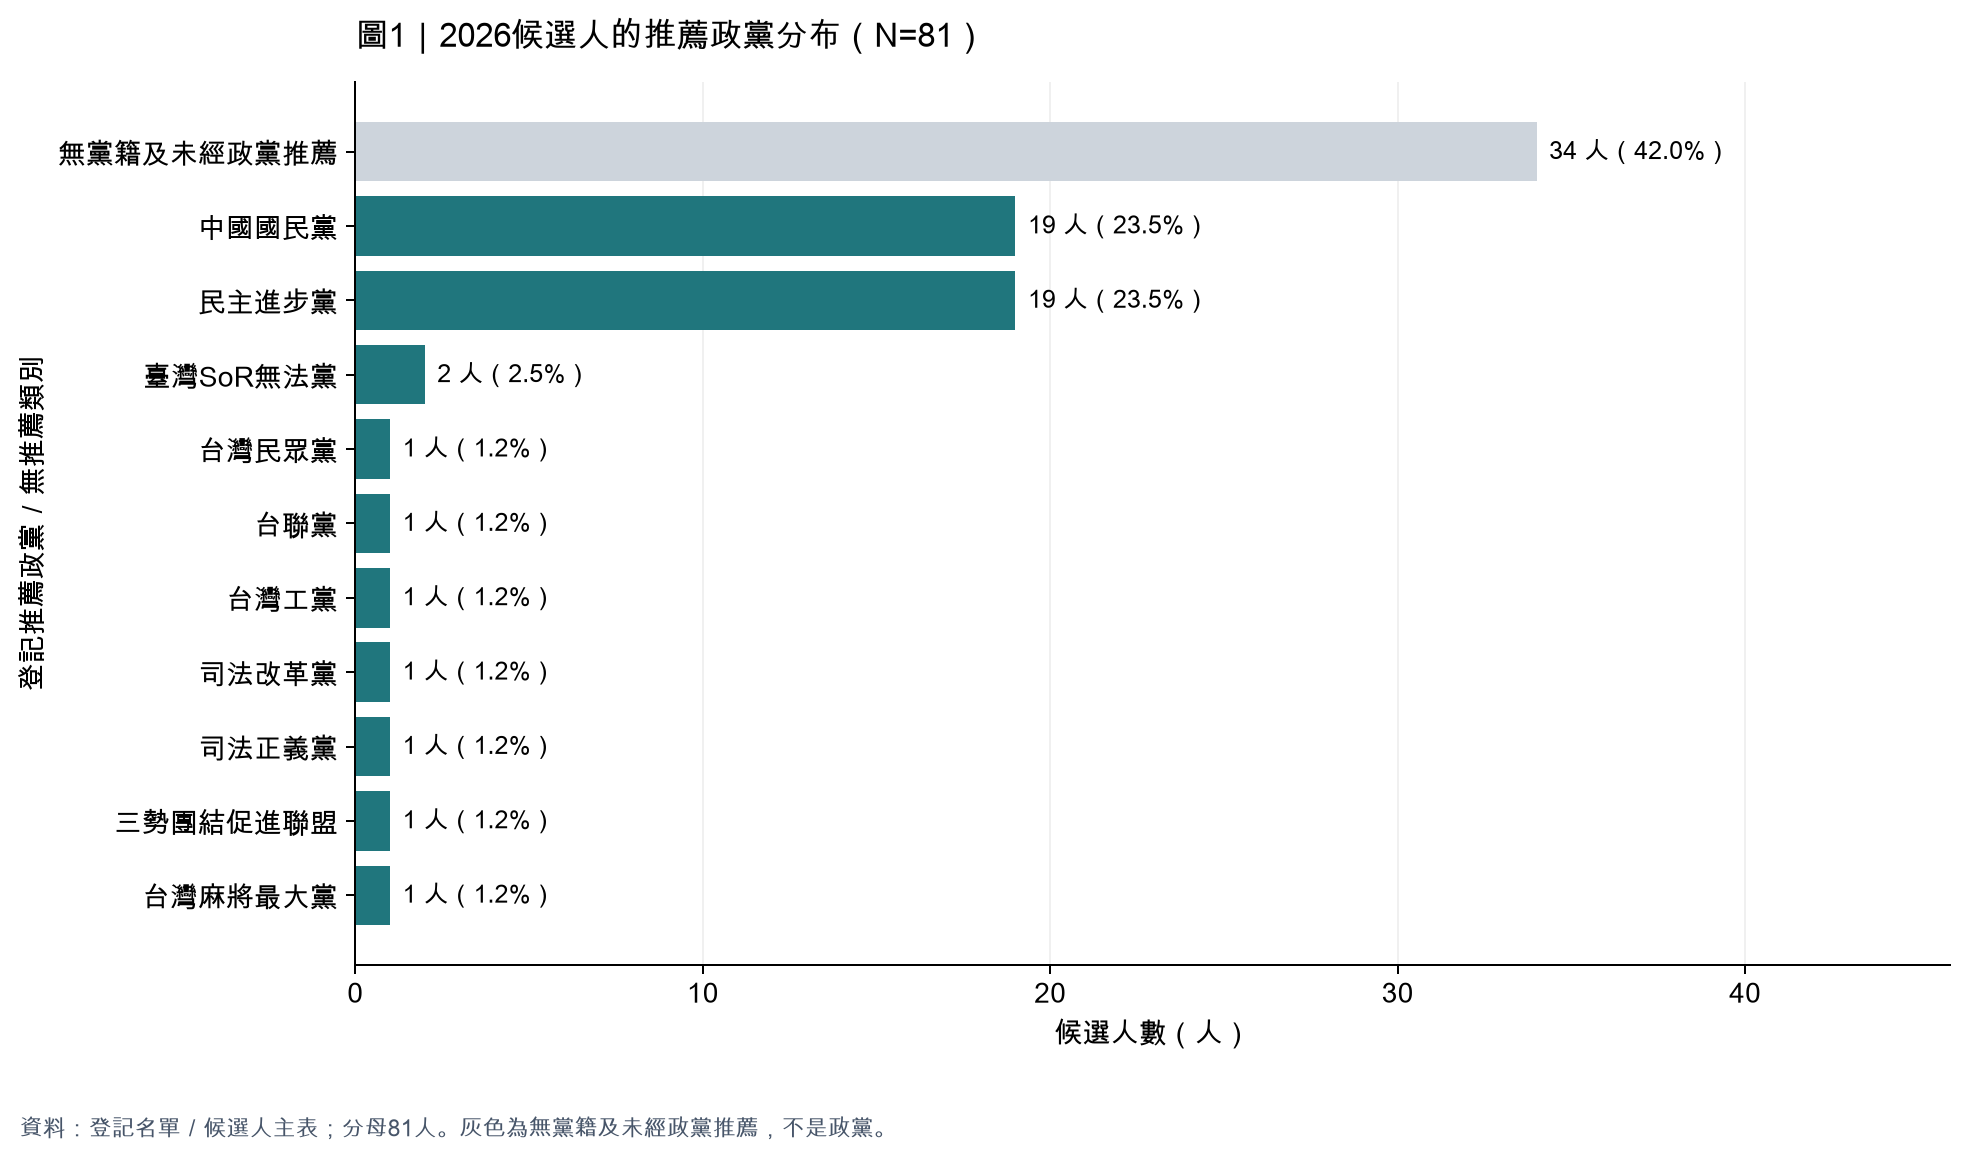

**如何解讀：**無黨籍及未經政黨推薦最多，共34人（42.0%）；民主進步黨與中國國民黨各19人，合計38人（46.9%）。另有8個具名推薦政黨合計9人。多數小黨只有1人，未來若按個別政黨比較，必須留意群內樣本很少。這是候選人組成，不是政黨支持率。

In [7]:
party_table=party_counts.rename_axis('推薦政黨／登記類別').reset_index(name='候選人數')
party_table['占全部81人（%）']=(party_table['候選人數']/N*100).round(1)
display(Markdown('**表2｜完整推薦政黨分布：列出全部11種類別，不截成前十名**'))
display(party_table)
plot_party=party_counts.sort_values(ascending=True,kind='stable')
fig,ax=plt.subplots(figsize=(11,6.5))
bars=ax.barh(plot_party.index,plot_party.values,color=[GREY if x==independent else TEAL for x in plot_party.index])
ax.bar_label(bars,labels=[f'{x} 人（{x/N:.1%}）' for x in plot_party.values],padding=5,fontsize=10)
ax.set_xlim(0,max(plot_party)*1.35);ax.set_xlabel('候選人數（人）');ax.set_ylabel('登記推薦政黨／無推薦類別')
ax.set_title('圖1｜2026候選人的推薦政黨分布（N=81）',loc='left',pad=14)
ax.grid(axis='x',alpha=.18);ax.set_axisbelow(True)
finish(fig,'01_party_distribution','資料：登記名單／候選人主表；分母81人。灰色為無黨籍及未經政黨推薦，不是政黨。')
major=int(party_counts.get('民主進步黨',0)+party_counts.get('中國國民黨',0))
display(Markdown(f'**如何解讀：**無黨籍及未經政黨推薦最多，共{party_counts[independent]}人（{party_counts[independent]/N:.1%}）；民主進步黨與中國國民黨各19人，合計{major}人（{major/N:.1%}）。另有8個具名推薦政黨合計9人。多數小黨只有1人，未來若按個別政黨比較，必須留意群內樣本很少。這是候選人組成，不是政黨支持率。'))


### 2. 候選人分布在哪些縣市？

每個縣市是一場首長選舉；下圖比較的是登記候選人數，**不按人口或選民數加權**。縣市人數較多不表示該縣市在母體或分析中應有較高權重。


**表3｜22縣市候選人數（N=81）**

,縣市,候選人數,占全部81人（%）
0,金門縣,7,8.6
1,臺北市,6,7.4
2,澎湖縣,6,7.4
3,高雄市,5,6.2
4,宜蘭縣,5,6.2
5,嘉義市,5,6.2
6,臺南市,4,4.9
7,彰化縣,4,4.9
8,雲林縣,4,4.9
9,花蓮縣,4,4.9


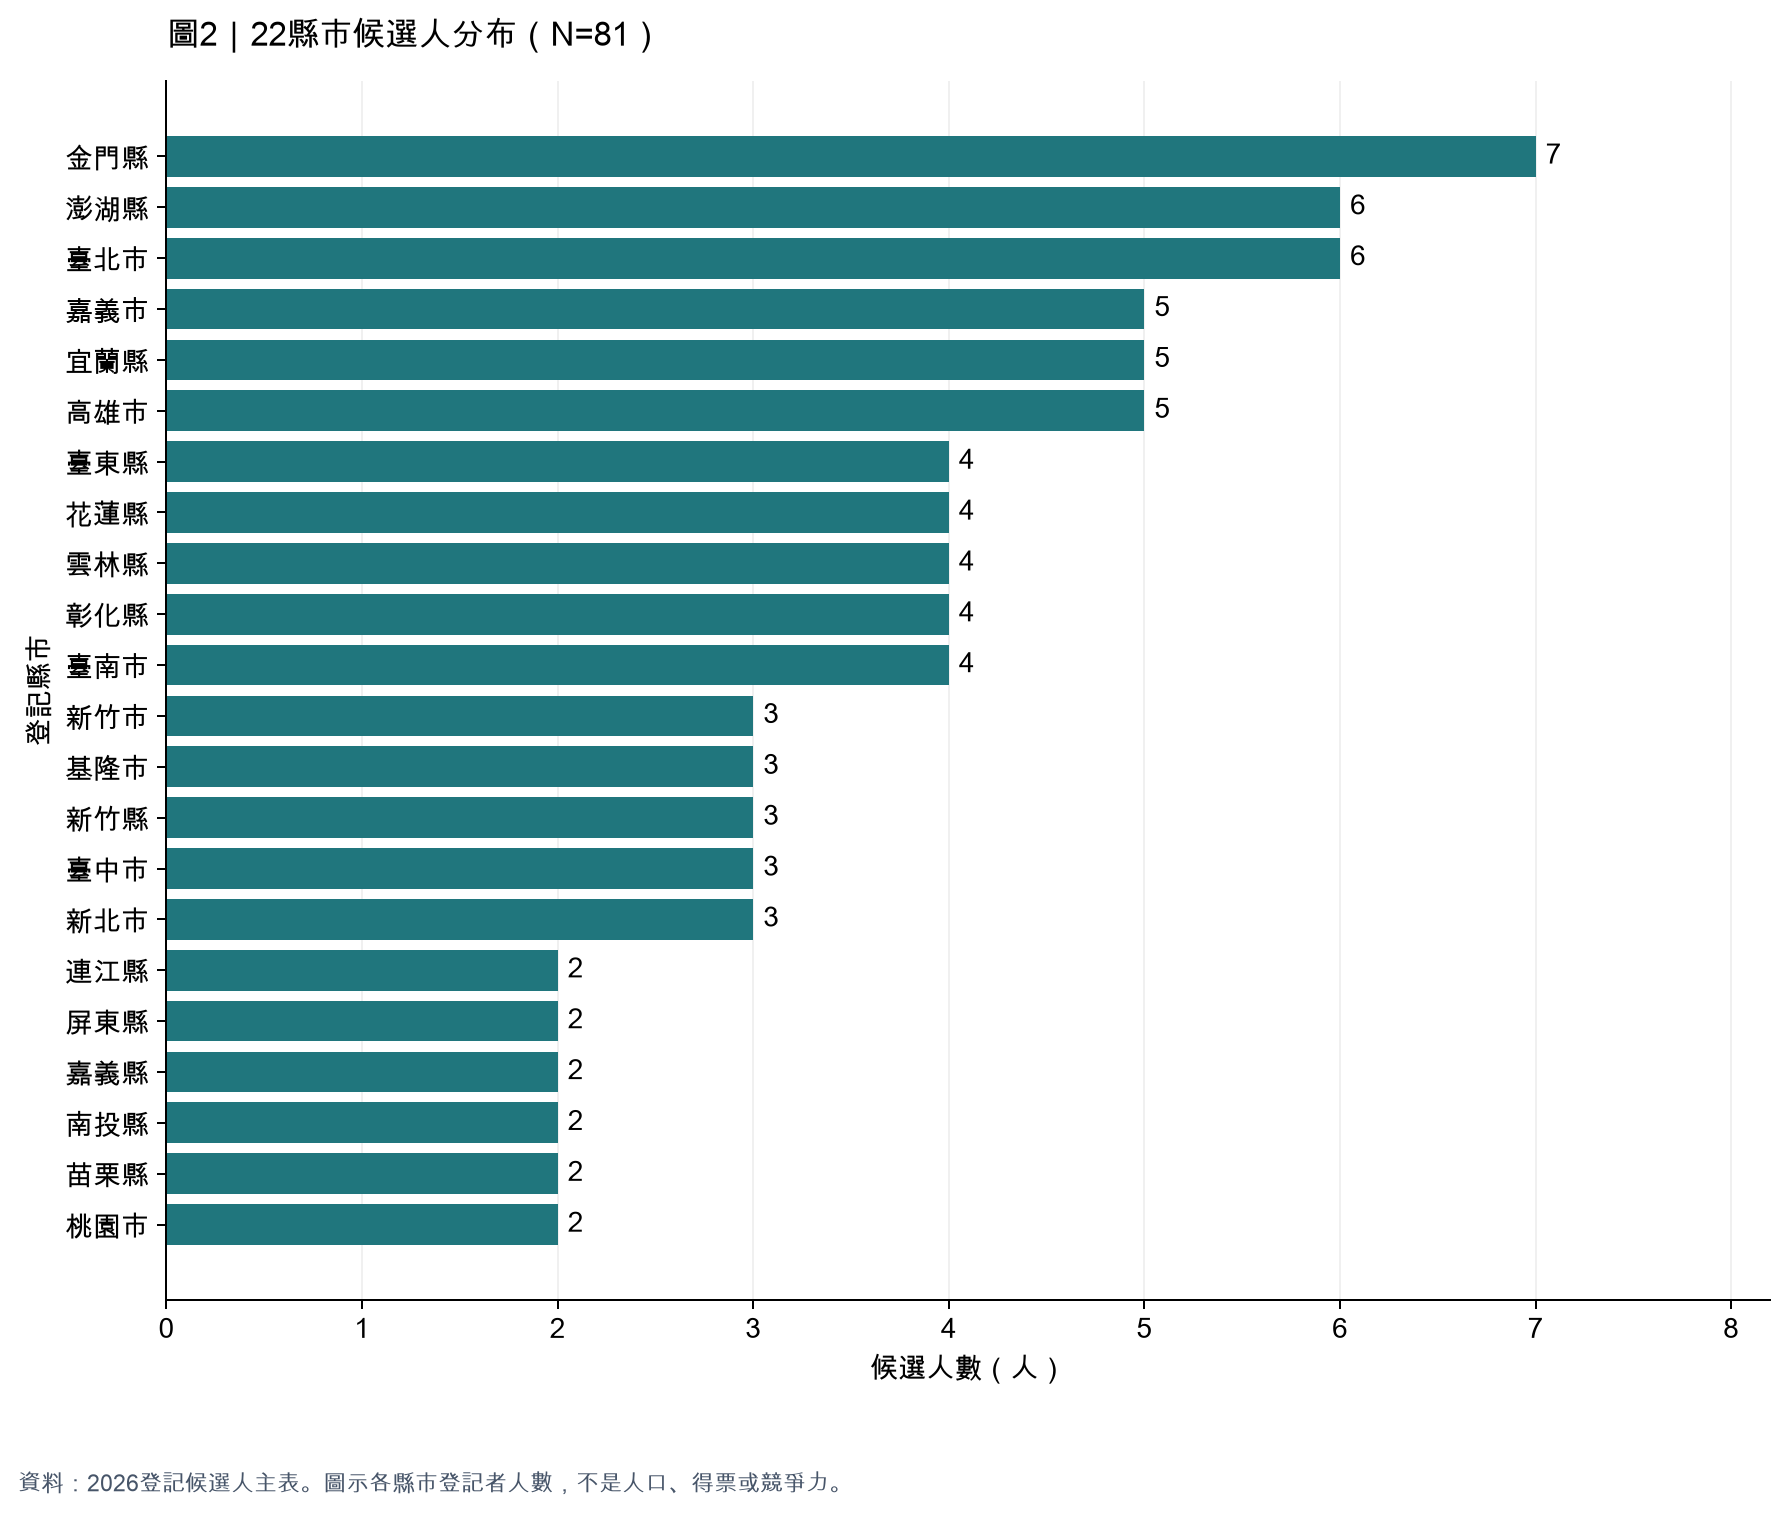

**如何解讀：**金門縣最多（7人），臺北市與澎湖縣各6人；最少的縣市為2人。後續比較候選人行為時，應同時考慮其所處的選區情境。

In [8]:
county_counts=df.county_city.value_counts()
county_table=county_counts.rename_axis('縣市').reset_index(name='候選人數')
county_table['占全部81人（%）']=(county_table.候選人數/N*100).round(1)
display(Markdown('**表3｜22縣市候選人數（N=81）**'));display(county_table)
plot_county=county_counts.sort_values(ascending=True,kind='stable')
fig,ax=plt.subplots(figsize=(10,8.5));bars=ax.barh(plot_county.index,plot_county.values,color=TEAL)
ax.bar_label(bars,fmt='%d',padding=4);ax.set_xlim(0,max(plot_county)+1.2)
ax.set_xticks(range(0,int(max(plot_county))+2));ax.set_xlabel('候選人數（人）');ax.set_ylabel('登記縣市')
ax.set_title('圖2｜22縣市候選人分布（N=81）',loc='left',pad=14);ax.grid(axis='x',alpha=.18);ax.set_axisbelow(True)
finish(fig,'02_county_distribution','資料：2026登記候選人主表。圖示各縣市登記者人數，不是人口、得票或競爭力。')
display(Markdown(f'**如何解讀：**金門縣最多（{county_counts["金門縣"]}人），臺北市與澎湖縣各6人；最少的縣市為{county_counts.min()}人。後續比較候選人行為時，應同時考慮其所處的選區情境。'))


### 3. 年齡與性別：涵蓋多少人、來源是什麼？

年齡圖統一使用`age_2026_from_media_birth_year`的79筆有效值，避免任意混合來源。定義為**2026減西元出生年**，不是投票日實足年齡。羅佩秦、魏造文缺出生年，不納入年齡摘要或直方圖。

性別分母為全部81人。男／女數值含使用者提供與媒體補充，不能稱為全部經政府確認；未知保留獨立一格，不推估。


**表4｜年度年齡摘要（媒體出生年；有效N=79，缺2人）**

,有效N,缺值數,平均,最小,第25百分位,中位數,第75百分位,最大,標準差
0,79,2,57.25,38.0,50.5,57.0,65.0,83.0,9.77


**表5｜性別標記分布（全部N=81，含未知）**

,公開資料性別標記,候選人數,占全部81人（%）
0,男,59,72.8
1,女,21,25.9
2,未知,1,1.2


**表6｜性別資料的證據層級（N=81；有來源不等於戶籍認證）**

,候選人數
證據層級,
官方／學會／歷史CEC紀錄,64
媒體補充,11
使用者提供，未獨立查證,5
未知,1


findfont: Failed to find font weight bold, now using 400.


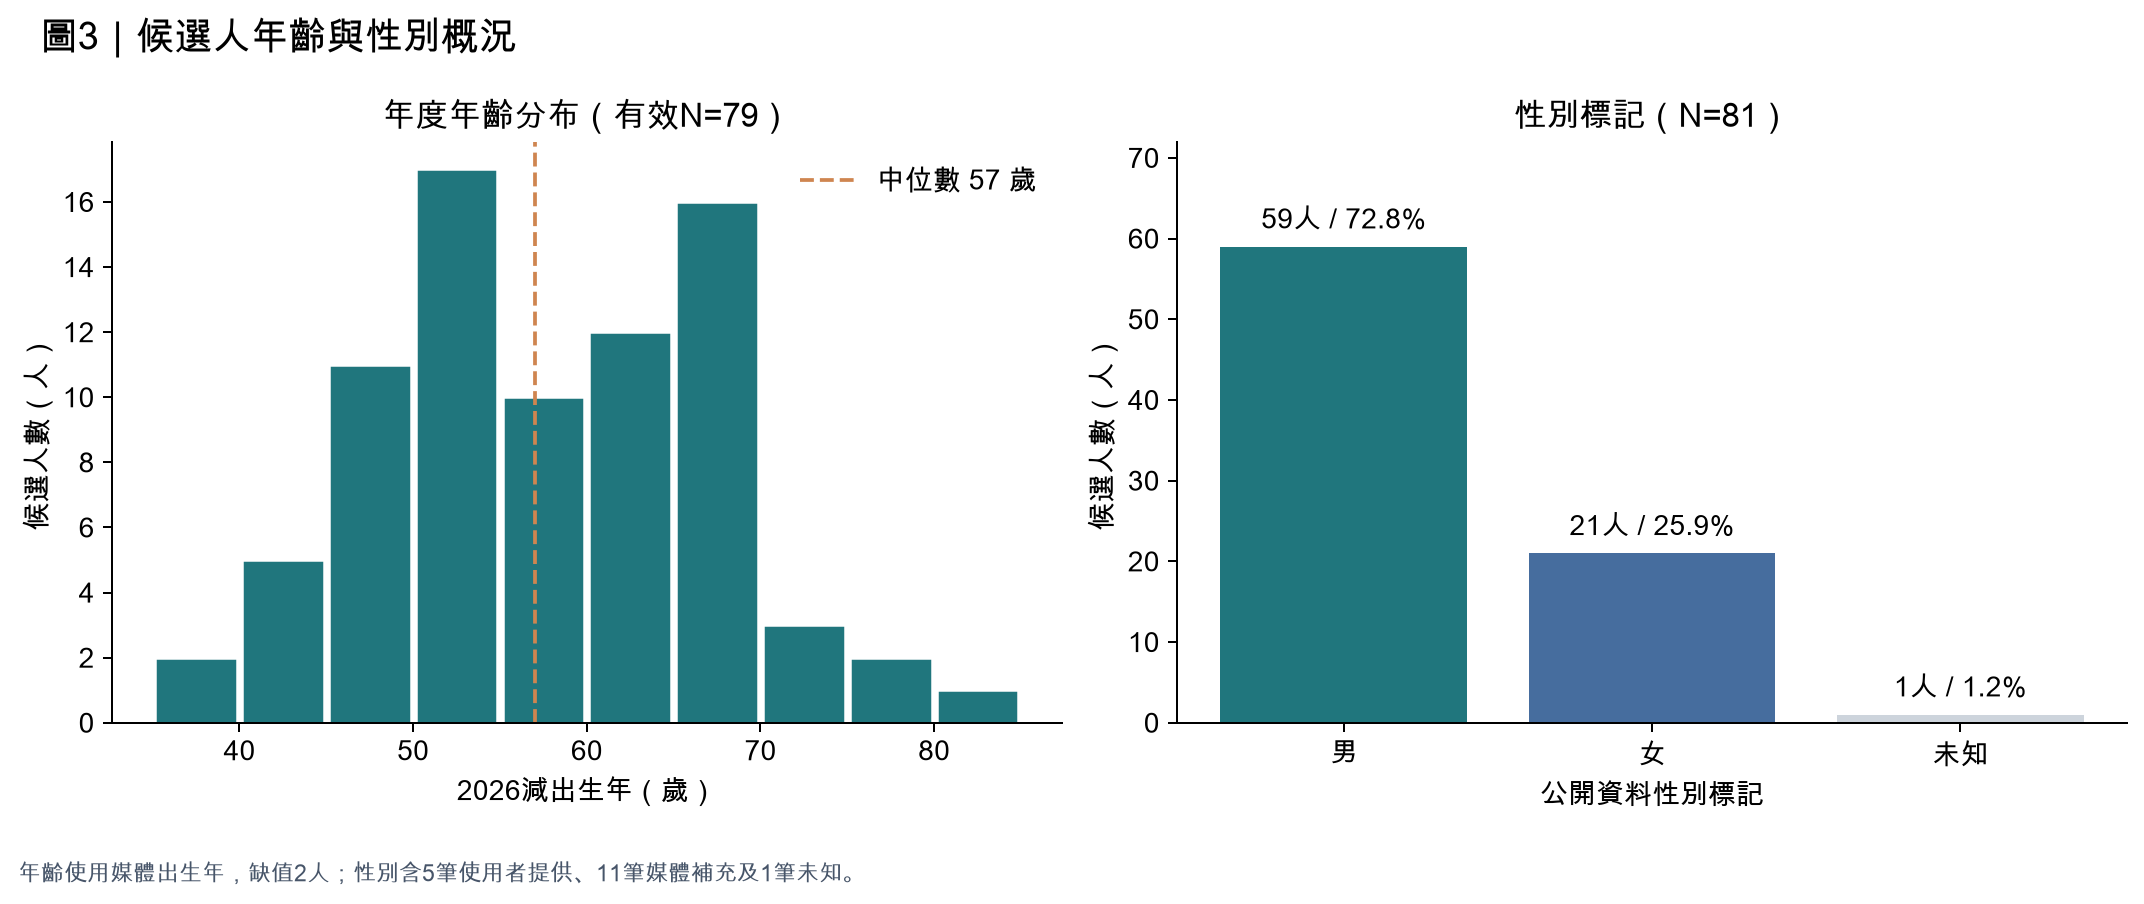

**如何解讀：**年度年齡介於38至83歲，中位數57歲，平均57.3歲。男性59人、女性21人、未知1人；性別來源分層見表6。這些分布描述現有候選人名單，未檢驗年齡或性別與競選策略的關係。

In [9]:
age=pd.to_numeric(df.age_2026_from_media_birth_year.replace('',np.nan),errors='coerce')
age_summary=pd.DataFrame([{'有效N':int(age.count()),'缺值數':int(age.isna().sum()),'平均':age.mean(),'最小':age.min(),'第25百分位':age.quantile(.25),'中位數':age.median(),'第75百分位':age.quantile(.75),'最大':age.max(),'標準差':age.std(ddof=1)}]).round(2)
display(Markdown('**表4｜年度年齡摘要（媒體出生年；有效N=79，缺2人）**'));display(age_summary)
sex_counts=df.sex_2026.replace('','未知').value_counts().reindex(['男','女','未知'],fill_value=0)
sex_table=sex_counts.rename_axis('公開資料性別標記').reset_index(name='候選人數')
sex_table['占全部81人（%）']=(sex_table.候選人數/N*100).round(1)
display(Markdown('**表5｜性別標記分布（全部N=81，含未知）**'));display(sex_table)
evidence_group=pd.Series('官方／學會／歷史CEC紀錄',index=master.index)
evidence_group.loc[master.sex_source_tier=='media_sex_supplement']='媒體補充'
evidence_group.loc[(master.sex_source_tier=='user_provided') & master.sex_2026.ne('')]='使用者提供，未獨立查證'
evidence_group.loc[master.sex_2026.eq('')]='未知'
display(Markdown('**表6｜性別資料的證據層級（N=81；有來源不等於戶籍認證）**'))
display(evidence_group.value_counts().rename_axis('證據層級').to_frame('候選人數'))
fig,axes=plt.subplots(1,2,figsize=(12,5))
bins=[35,40,45,50,55,60,65,70,75,80,85]
axes[0].hist(age.dropna(),bins=bins,color=TEAL,edgecolor='white',rwidth=.94)
axes[0].axvline(age.median(),color=ORANGE,ls='--',label=f'中位數 {age.median():.0f} 歲')
axes[0].set(title='年度年齡分布（有效N=79）',xlabel='2026減出生年（歲）',ylabel='候選人數（人）');axes[0].legend(frameon=False)
bars=axes[1].bar(sex_counts.index,sex_counts.values,color=[TEAL,BLUE,GREY]);axes[1].bar_label(bars,labels=[f'{x}人 / {x/N:.1%}' for x in sex_counts],padding=5)
axes[1].set(title='性別標記（N=81）',xlabel='公開資料性別標記',ylabel='候選人數（人）',ylim=(0,72))
fig.suptitle('圖3｜候選人年齡與性別概況',x=.02,ha='left',fontweight='bold',fontsize=15)
finish(fig,'03_age_and_sex','年齡使用媒體出生年，缺值2人；性別含5筆使用者提供、11筆媒體補充及1筆未知。')
display(Markdown(f'**如何解讀：**年度年齡介於{age.min():.0f}至{age.max():.0f}歲，中位數{age.median():.0f}歲，平均{age.mean():.1f}歲。男性59人、女性21人、未知1人；性別來源分層見表6。這些分布描述現有候選人名單，未檢驗年齡或性別與競選策略的關係。'))


### 4. 學歷：有文字資料，不代表已統一分類

目前分開保留官方人物頁、歷史CEC類別、媒體文字；**同一人可能同時有三種資料，不能把來源人數相加當成候選人總數**。媒體文字包含遠見補充，仍須確認畢業／肄業／在學、學位與觀察年份，才適合建立2026最高學歷分組。

下圖只呈現已接受身分配對的**歷史CEC教育類別**，並保留31人的缺值；不是2026最高學歷分布，也不把缺值視為學歷較低。


**表7｜學歷資料涵蓋（來源有重疊；分母81人）**

,資料層次,有資料人數,占全部81人（%）
0,官方人物頁學歷文字,25,30.9
1,歷史CEC教育類別,50,61.7
2,媒體學歷文字（含遠見補充）,78,96.3
3,至少一種來源有學歷資訊,79,97.5


**表8｜歷史CEC教育類別（50人有值，31人未取得）**

,候選人數
歷史教育類別,
高中(職),2
大學,14
碩士,22
博士,11
其他,1
歷史CEC未取得,31


**歷史CEC觀察年份（非畢業年）：**

,候選人數
觀察年份,
2010,1
2020,2
2022,27
2024,20


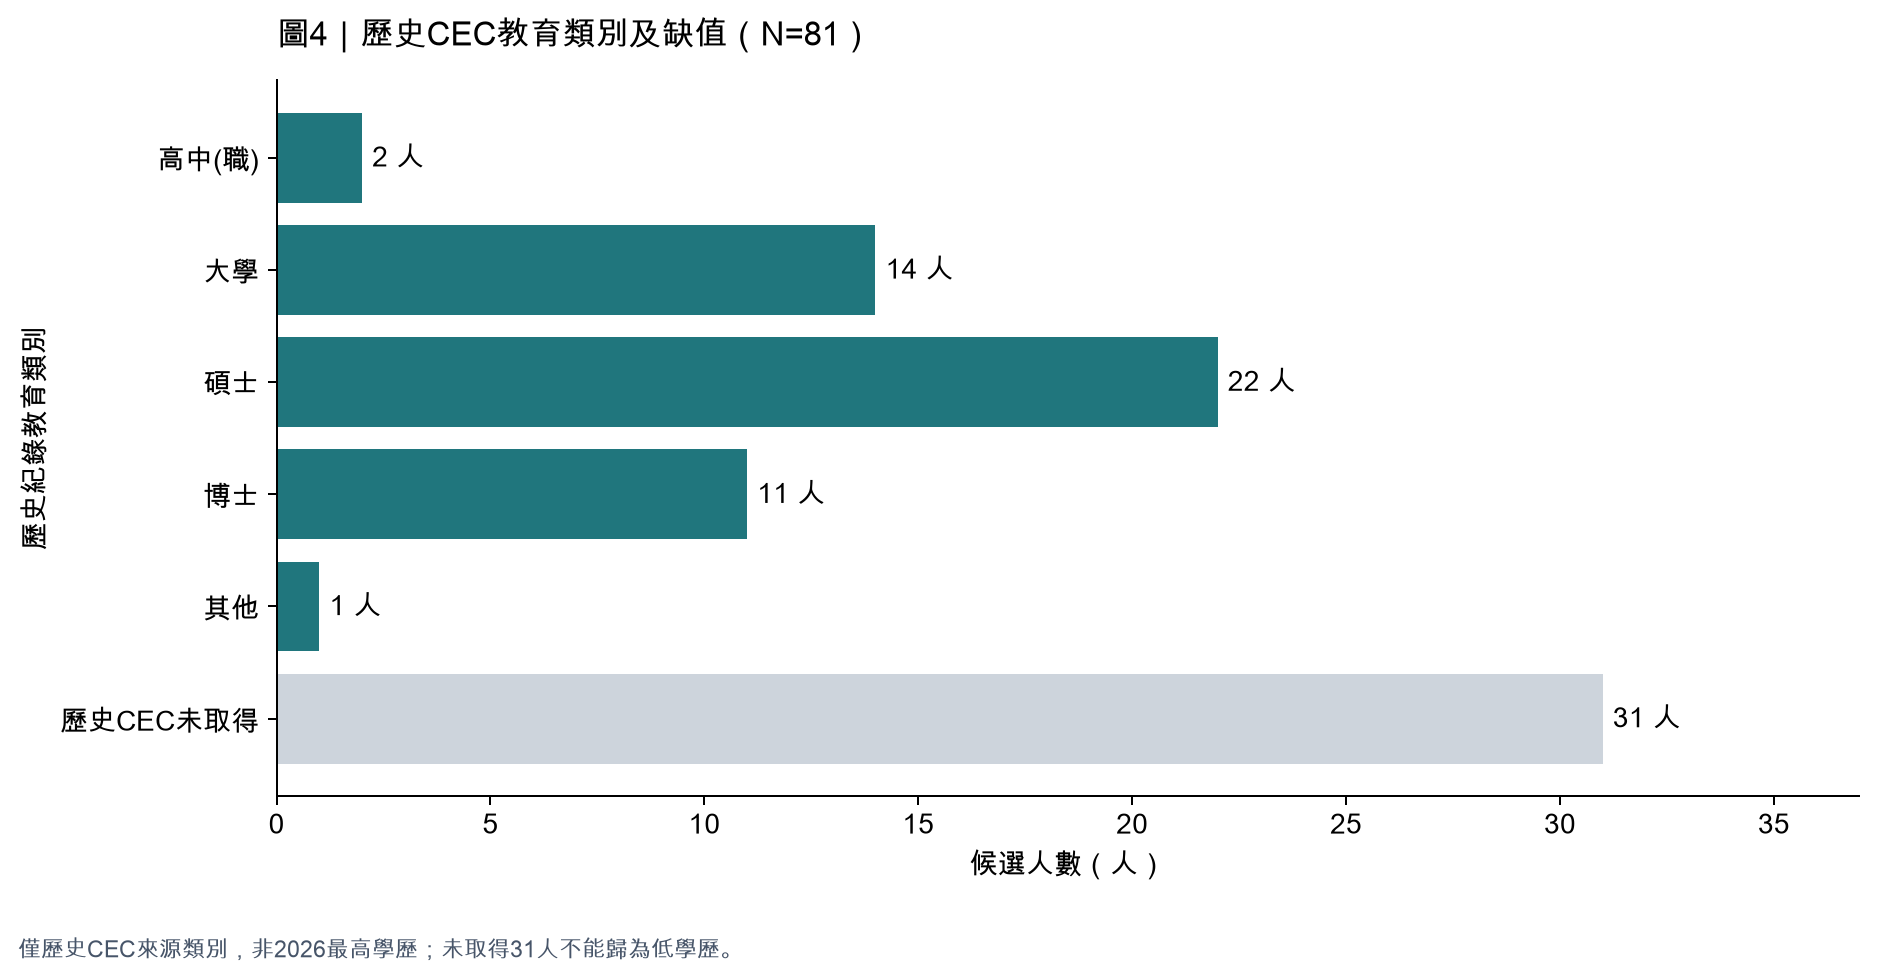

**如何解讀：**至少一種來源有學歷資訊者79人；仍缺魏造文、王義成。歷史CEC類別中碩士22人、博士11人、大學14人、高中(職)2人、其他1人，另31人沒有該來源類別。羅佩秦的遠見學歷文字已列「學位待核實」，不因此新增已認證學位或自動教育分組。

In [10]:
education_cols=['education_profile_as_captured','education_latest_cec','education_media_supplement']
edu_any=df[education_cols].ne('').any(axis=1)
education_coverage=pd.DataFrame({'資料層次':['官方人物頁學歷文字','歷史CEC教育類別','媒體學歷文字（含遠見補充）','至少一種來源有學歷資訊'],
    '有資料人數':[int(df[c].ne('').sum()) for c in education_cols]+[int(edu_any.sum())]})
education_coverage['占全部81人（%）']=(education_coverage.有資料人數/N*100).round(1)
display(Markdown('**表7｜學歷資料涵蓋（來源有重疊；分母81人）**'));display(education_coverage)
edu_counts=df.education_latest_cec.replace('','歷史CEC未取得').value_counts().reindex(['高中(職)','大學','碩士','博士','其他','歷史CEC未取得'],fill_value=0)
display(Markdown('**表8｜歷史CEC教育類別（50人有值，31人未取得）**'));display(edu_counts.rename_axis('歷史教育類別').to_frame('候選人數'))
display(Markdown('**歷史CEC觀察年份（非畢業年）：**'));display(df.loc[df.education_latest_cec_year!='','education_latest_cec_year'].value_counts().sort_index().rename_axis('觀察年份').to_frame('候選人數'))
fig,ax=plt.subplots(figsize=(10.5,5.5));bars=ax.barh(edu_counts.index[::-1],edu_counts.values[::-1],color=[GREY if x=='歷史CEC未取得' else TEAL for x in edu_counts.index[::-1]])
ax.bar_label(bars,labels=[f'{x} 人' for x in edu_counts.values[::-1]],padding=4);ax.set_xlim(0,max(edu_counts)+6)
ax.set_title('圖4｜歷史CEC教育類別及缺值（N=81）',loc='left',pad=14);ax.set_xlabel('候選人數（人）');ax.set_ylabel('歷史紀錄教育類別')
finish(fig,'04_historical_education','僅歷史CEC來源類別，非2026最高學歷；未取得31人不能歸為低學歷。')
display(Markdown(f'**如何解讀：**至少一種來源有學歷資訊者{edu_any.sum()}人；仍缺魏造文、王義成。歷史CEC類別中碩士22人、博士11人、大學14人、高中(職)2人、其他1人，另31人沒有該來源類別。羅佩秦的遠見學歷文字已列「學位待核實」，不因此新增已認證學位或自動教育分組。'))


### 5. 曾參選證據：不能當成勝選次數

兩種首次參選欄目前只含`0`及空白：`0`表示找到曾參選證據，**不是勝選，也不是第一次參選**；空白表示終生查核未完成。沒有找到歷史紀錄不能填首次參選`1`。兩種定義互相關聯，不能把人數相加。


**表9｜兩種首次參選欄位的證據狀態（每列N=81）**

,已找到曾參選證據（首次=0）,明確認定首次（首次=1）,尚未完成查核
查核範圍,,,
縣市長參選史,21,0,60
任何民選公職參選史,56,0,25


findfont: Failed to find font weight bold, now using 400.


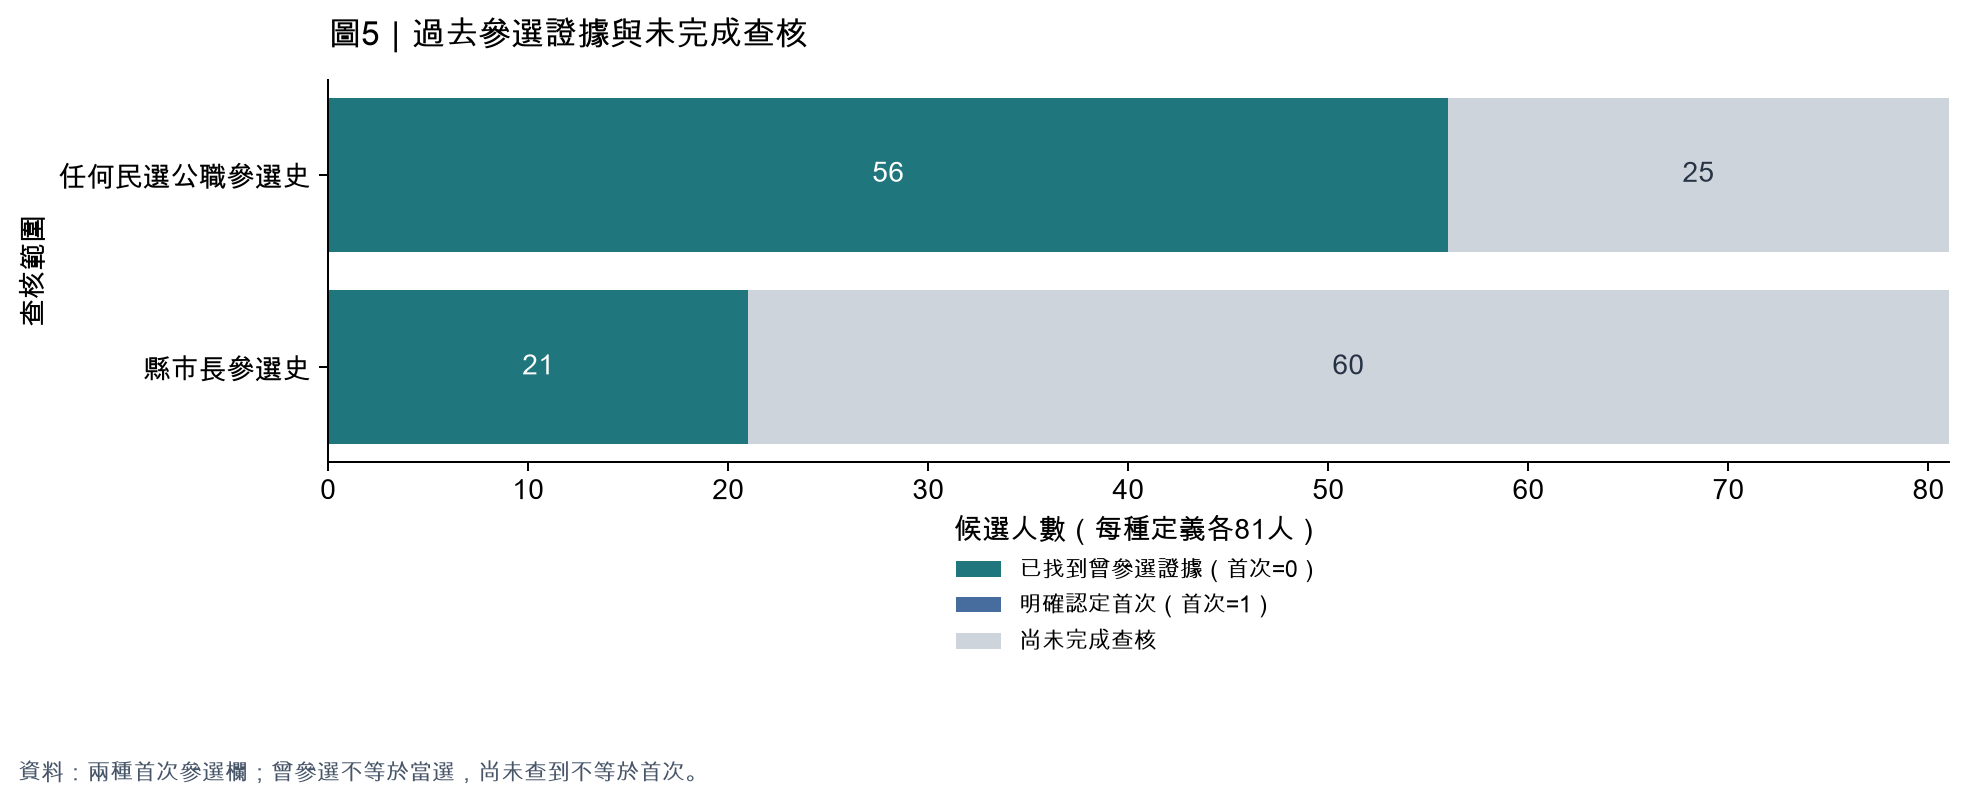

**如何解讀：**21人有過去縣市長參選證據，56人有過去任何民選公職參選證據；分別有60人與25人尚未完成終生查核。目前沒有任何人被確認並填為首次參選=1。圖中灰色不是「從未參選」。

In [11]:
history_rows=[]
for column,label in [('first_time_mayor_lifetime','縣市長參選史'),('first_time_any_elected_office','任何民選公職參選史')]:
    history_rows.append({'查核範圍':label,'已找到曾參選證據（首次=0）':int(df[column].eq('0').sum()),'明確認定首次（首次=1）':int(df[column].eq('1').sum()),'尚未完成查核':int(df[column].eq('').sum())})
history_table=pd.DataFrame(history_rows).set_index('查核範圍')
display(Markdown('**表9｜兩種首次參選欄位的證據狀態（每列N=81）**'));display(history_table)
fig,ax=plt.subplots(figsize=(11,4.5));left=np.zeros(len(history_table))
for col,color in zip(history_table.columns,[TEAL,BLUE,GREY]):
    values=history_table[col].to_numpy();bars=ax.barh(history_table.index,values,left=left,color=color,label=col)
    for bar,value,start in zip(bars,values,left):
        if value:ax.text(start+value/2,bar.get_y()+bar.get_height()/2,str(value),ha='center',va='center',color='white' if color!=GREY else '#273344',fontweight='bold')
    left+=values
ax.set(xlim=(0,N),xlabel='候選人數（每種定義各81人）',ylabel='查核範圍');ax.set_title('圖5｜過去參選證據與未完成查核',loc='left',pad=14)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.2),ncol=1,frameon=False,fontsize=9)
finish(fig,'05_prior_candidacy_evidence','資料：兩種首次參選欄；曾參選不等於當選，尚未查到不等於首次。')
display(Markdown('**如何解讀：**21人有過去縣市長參選證據，56人有過去任何民選公職參選證據；分別有60人與25人尚未完成終生查核。目前沒有任何人被確認並填為首次參選=1。圖中灰色不是「從未參選」。'))


### 6. 哪些資料夠完整？下一步補什麼？

下圖衡量「我們是否已取得資料或正面證據」，**不是候選人是否具有該特徵**。例如官方FB連結未核實不代表沒有FB，現任狀態空白不代表不是現任，完整貼文尚未蒐集不代表零貼文。


**表10｜目前資料涵蓋與蒐集進度（每列分母81人）**

,欄位或蒐集項目,已有資料／證據,缺值或尚未完成,涵蓋率（%）
0,登記縣市與推薦政黨,81,0,100.0
1,性別（含媒體與使用者）,80,1,98.8
2,出生年（媒體補充）,79,2,97.5
3,學歷（任一已存來源）,79,2,97.5
4,完整生日（有核對依據）,55,26,67.9
5,曾參選任一公職的正面證據,56,25,69.1
6,曾參選縣市長的正面證據,21,60,25.9
7,已核實官方FB連結,8,73,9.9
8,已找到競選網站,8,73,9.9
9,已填現任狀態,5,76,6.2


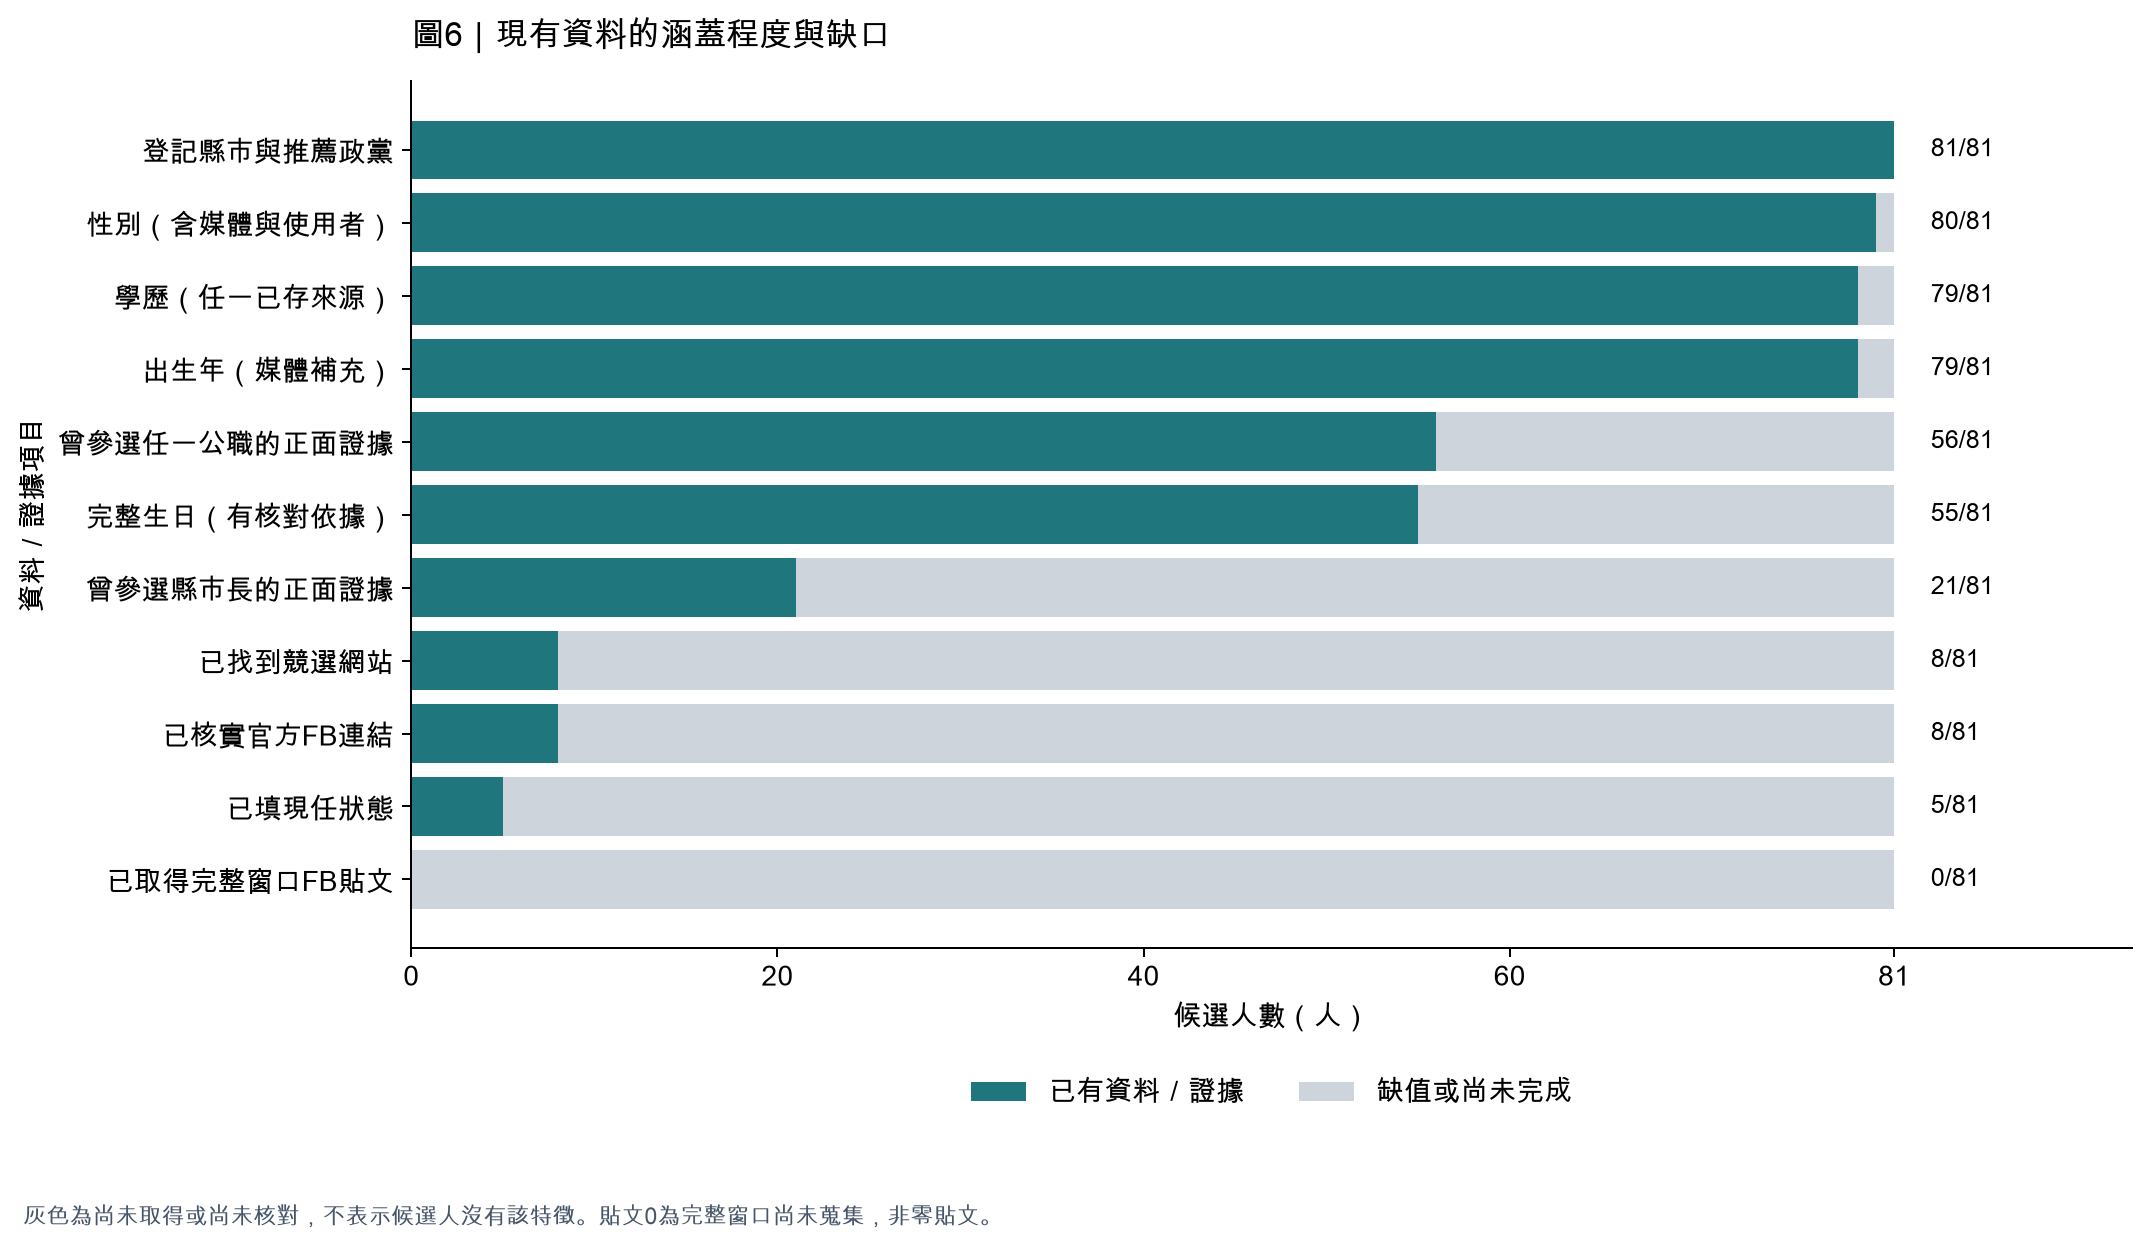

**如何解讀：**名單與部分背景已接近完整，但官方帳號核實、現任狀態、首次參選的終生查核及策略材料仍有明顯缺口。官網已存459個段落，也不能當成459項政策；尚未切分與編碼。後續先確認樣本及官方帳號，再完成窗口貼文、政策與視覺材料的蒐集。

In [12]:
coverage_items={
 '登記縣市與推薦政黨':int((df.county_city.ne('') & df.party_at_registration.ne('')).sum()),
 '性別（含媒體與使用者）':int(df.sex_2026.ne('').sum()),
 '出生年（媒體補充）':int(df.media_birth_year.ne('').sum()),
 '學歷（任一已存來源）':int(edu_any.sum()),
 '完整生日（有核對依據）':int(df.birth_date_verified.ne('').sum()),
 '曾參選任一公職的正面證據':int(df.first_time_any_elected_office.eq('0').sum()),
 '曾參選縣市長的正面證據':int(df.first_time_mayor_lifetime.eq('0').sum()),
 '已核實官方FB連結':int(master.official_facebook_url.ne('').sum()),
 '已找到競選網站':int(master.official_campaign_website.ne('').sum()),
 '已填現任狀態':int(df.incumbency_2026.ne('').sum()),
 '已取得完整窗口FB貼文':0}
coverage_table=pd.DataFrame([{'欄位或蒐集項目':key,'已有資料／證據':value,'缺值或尚未完成':N-value,'涵蓋率（%）':round(value/N*100,1)} for key,value in coverage_items.items()])
display(Markdown('**表10｜目前資料涵蓋與蒐集進度（每列分母81人）**'));display(coverage_table)
ordered=coverage_table.sort_values('已有資料／證據',ascending=True,kind='stable')
fig,ax=plt.subplots(figsize=(12,7));bars=ax.barh(ordered['欄位或蒐集項目'],ordered['已有資料／證據'],color=TEAL,label='已有資料／證據')
ax.barh(ordered['欄位或蒐集項目'],ordered['缺值或尚未完成'],left=ordered['已有資料／證據'],color=GREY,label='缺值或尚未完成')
for bar,value in zip(bars,ordered['已有資料／證據']):
    ax.text(83,bar.get_y()+bar.get_height()/2,f'{value}/81',va='center',fontsize=10)
ax.set_xlim(0,94);ax.set_xticks([0,20,40,60,81]);ax.set_xlabel('候選人數（人）');ax.set_ylabel('資料／證據項目')
ax.set_title('圖6｜現有資料的涵蓋程度與缺口',loc='left',pad=14);ax.legend(loc='upper center',bbox_to_anchor=(.5,-.12),ncol=2,frameon=False)
finish(fig,'06_collection_coverage','灰色為尚未取得或尚未核對，不表示候選人沒有該特徵。貼文0為完整窗口尚未蒐集，非零貼文。')
display(Markdown('**如何解讀：**名單與部分背景已接近完整，但官方帳號核實、現任狀態、首次參選的終生查核及策略材料仍有明顯缺口。官網已存459個段落，也不能當成459項政策；尚未切分與編碼。後續先確認樣本及官方帳號，再完成窗口貼文、政策與視覺材料的蒐集。'))


### 7. 讀完後應記住的限制

- 這是已登記候選人的描述，不是選民抽樣；人數比例不代表民意支持率，未在此進行顯著性檢定或因果推論。
- 81人保留，不依有無資料排除；將來做分群或策略比較時，需另寫樣本與缺值規則。
- 年齡是年度差值；學歷有來源年代與用字差異；性別含五筆使用者輸入；這些限制不因畫圖而消失。
- 初步姓名命中、已找到過去參選證據、當選紀錄是不同概念。這份表沒有把曾參選當成曾當選。
- 媒體政見摘要不能直接代替候選人原文計算議題占比；官網段落未完成政策編碼。
- 本次只更新資料說明與圖形，不改任何CSV或研究分組。圖形為資料的精確計數／直方圖，不呈現母體平均估計，未加抽樣信賴區間。

### 圖形檔案

六張PNG另存於本Notebook旁的`assets/candidates_2026_simple_documentation/`，Notebook也保留實際圖形輸出。所有圖與表由固定版本CSV重現；來源網址與檔案定位請回完整主表及來源觀察表。


### Assertions

In [13]:
verify_input_sha256(project_file(SOURCE,'processed'),SOURCE_HASH)
master=pd.read_csv(project_file(SOURCE,'processed'),dtype=str,keep_default_na=False)
assert len(df)==81 and df.candidate_key.is_unique
pd.testing.assert_frame_equal(df,master[COLUMNS])
print('Exact projection verified; no rows or values changed.')
assert list(df.columns)==COLUMNS and len(COLUMNS)==21
assert set(df.sex_2026)<=set(["男","女",""])
for column in ["first_time_mayor_lifetime","first_time_any_elected_office"]:
    assert set(df[column])<=set(["0","1",""])
assert (df.sex_2026!="").sum()==80
print("Schema, categories and source projection checks passed; missing values retained.")
assert party_counts.sum()==N and county_counts.sum()==N
assert sex_counts.sum()==N and age.count()==79
assert history_table.sum(axis=1).eq(N).all()
assert all((ASSETS/name).is_file() for name in ["01_party_distribution.png","02_county_distribution.png","03_age_and_sex.png","04_historical_education.png","05_prior_candidacy_evidence.png","06_collection_coverage.png"])
print("All overview totals and six saved figures verified.")

Exact projection verified; no rows or values changed.
Schema, categories and source projection checks passed; missing values retained.
All overview totals and six saved figures verified.
